# Predicting Cardiovascular Disease from Routine Health Check-up Data
### DS3000 — Introduction to Machine Learning · Course Project · Fall 2026

**Group 1:** Kristina, Romy, Rakan, Brandon
**Dataset:** #19 — Cardiovascular Disease (OpenML, dataset ID 45547)

---

### Problem statement
Cardiovascular disease is one of the leading causes of death worldwide, and many cases can be prevented
when people at risk are identified early. In this project, we investigate whether the presence of
cardiovascular disease can be predicted from information that is routinely collected during a standard
medical check-up, such as age, blood pressure, cholesterol and lifestyle habits.

### Task
This is a **supervised binary classification** problem. Each row in the dataset represents one patient,
and the target variable `cardio` records whether that patient has cardiovascular disease (`1`) or not (`0`).
The models we build will learn from patients whose outcome is known, and will then be evaluated on their
ability to correctly classify patients they have not seen before.

### Notebook structure
1. Setup
2. Data loading and description
3. Exploratory data analysis
4. Data cleaning
5. Feature engineering
6. Train / validation / test split
7. Feature scaling
8. Evaluation setup
9. Baseline models
10. Stage 1 summary

## 1. Setup

All libraries used in this notebook are imported in a single cell so that every dependency is visible in one
place and the notebook can be run from top to bottom without errors.

| Library | Purpose |
|---|---|
| `numpy` | Numerical operations on arrays |
| `pandas` | Loading and manipulating tabular data (DataFrames) |
| `matplotlib` / `seaborn` | Data visualisation |

We also define a single random seed, `SEED = 42`. Several steps later in the project involve randomness,
such as shuffling the data before splitting it or initialising certain models. Fixing the seed ensures
that these steps produce identical results every time the notebook is run, which makes our results
**reproducible** for every group member and for anyone evaluating the project. The specific value has no
special meaning; what matters is that the same value is used consistently throughout.

In [1]:
# Core libraries
import numpy as np                # numerical operations
import pandas as pd               # tabular data (DataFrames)
import matplotlib.pyplot as plt   # plotting
import seaborn as sns             # statistical plots built on matplotlib

# Random seed used for every random operation in this notebook (for reproducibility)
SEED = 42

print("Libraries imported successfully. Random seed =", SEED)

Libraries imported successfully. Random seed = 42


## 2. Data Loading and Description

### 2.1 Loading the dataset
The dataset is stored in the repository as `data/cardio.arff`. It was obtained from OpenML
(https://www.openml.org/d/45547) and is kept locally so that the notebook can run without an internet connection.

The file is in **ARFF format** (Attribute-Relation File Format), a plain-text format used by OpenML. It begins
with a 47-line header that describes the dataset and its attributes, and the patient records begin on line 48.
For this reason, the header is skipped when reading the file, and the column names are supplied manually
in the same order in which they are declared in the header.

A **relative path** (`data/cardio.arff`) is used so that the notebook runs on any machine where the repository
has been cloned, without needing to change any file locations. When the notebook is run in an environment
that does not contain the repository files, such as Google Colab, the same file is read directly from the
project's GitHub repository instead. In both cases the data is identical, so the results are the same.

In [2]:
import os

# Column names, in the order they are declared in the ARFF header
column_names = ["id", "age", "gender", "height", "weight", "ap_hi", "ap_lo",
                "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]

# Use the local copy in the repository if it exists (e.g. running in Jupyter on our own laptops).
# Otherwise (e.g. running in Google Colab, which has no access to our local files),
# read the same file directly from our GitHub repository.
DATA_PATH = "data/cardio.arff"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "https://raw.githubusercontent.com/Kristina-Kojic/3000-AISE/main/data/cardio.arff"

# Skip the 47-line ARFF header; the file has no header row, so column names are supplied manually
df = pd.read_csv(DATA_PATH, skiprows=47, header=None, names=column_names)

print("Data loaded from:", DATA_PATH)
print("Number of rows (patients):", df.shape[0])
print("Number of columns:        ", df.shape[1])
df.head()

Data loaded from: data/cardio.arff
Number of rows (patients): 70000
Number of columns:         13


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110.0,80.0,1,1,0,0,1,0
1,1,20228,1,156,85.0,140.0,90.0,3,1,0,0,1,1
2,2,18857,1,165,64.0,130.0,70.0,3,1,0,0,0,1
3,3,17623,2,169,82.0,150.0,100.0,1,1,0,0,1,1
4,4,17474,1,156,56.0,100.0,60.0,1,1,0,0,0,0


### 2.2 Data types
Before any analysis, we confirm that every column was read as a numeric type. If a column had been read as
text, this would indicate a loading problem (for example, a stray header line being treated as data).

In [3]:
df.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi          float64
ap_lo          float64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

### 2.3 Class balance of the target variable
We count the number of patients in each class of `cardio`. The class balance determines which evaluation
metrics are meaningful: when one class is much more common than the other, accuracy alone becomes misleading,
because a model could achieve a high accuracy simply by always predicting the majority class.

In [4]:
class_counts = df["cardio"].value_counts()
class_percent = df["cardio"].value_counts(normalize=True) * 100

pd.DataFrame({"Count": class_counts, "Percentage (%)": class_percent.round(2)})

,Count,Percentage (%)
cardio,,
0,35021,50.03
1,34979,49.97


### 2.4 Description of the variables
The dataset description groups the features into three types: **objective** (factual information),
**examination** (results of the medical examination) and **subjective** (information reported by the patient).

| Column | Description | Feature type | Unit / values |
|---|---|---|---|
| `id` | Record identifier | — | Integer. Not a predictive feature; it will be removed during cleaning |
| `age` | Age of the patient | Objective | **Days** (to be converted to years during cleaning) |
| `gender` | Gender of the patient | Objective | Categorical code: 1 or 2 |
| `height` | Height | Objective | cm |
| `weight` | Weight | Objective | kg |
| `ap_hi` | Systolic blood pressure (upper value) | Examination | mmHg |
| `ap_lo` | Diastolic blood pressure (lower value) | Examination | mmHg |
| `cholesterol` | Cholesterol level | Examination | 1 = normal, 2 = above normal, 3 = well above normal |
| `gluc` | Glucose level | Examination | 1 = normal, 2 = above normal, 3 = well above normal |
| `smoke` | Smoking status | Subjective | 0 = no, 1 = yes |
| `alco` | Alcohol intake | Subjective | 0 = no, 1 = yes |
| `active` | Physical activity | Subjective | 0 = no, 1 = yes |
| `cardio` | **Target:** presence of cardiovascular disease | — | 0 = absent, 1 = present |

### 2.5 Initial observations
- The dataset contains **70,000 patients** and **13 columns**: 11 input features, one identifier (`id`)
  and one target variable (`cardio`).
- All columns were loaded as numeric types, confirming that the file was read correctly.
- The target is **almost perfectly balanced** (approximately 50% of patients with the disease and 50% without).
  As a result, accuracy is a fair summary metric for this problem. However, because failing to detect a patient
  who has the disease (a false negative) is more serious in a medical screening context than a false alarm,
  recall will also be an important metric when comparing models.
- `cholesterol` and `gluc` are **ordinal** variables: their values follow a natural order
  (normal < above normal < well above normal), so their numeric codes can be used directly.
- Three features (`smoke`, `alco`, `active`) are **self-reported** by the patient, which means they may be less
  reliable than measured values. This is a potential limitation that will be revisited later in the project.

## 3. Exploratory Data Analysis (EDA)

Before cleaning the data or training any model, we examine the dataset to understand its structure and to
identify any problems that could affect our results. In particular, we look for missing values, duplicate
records and values that are physically or medically impossible, and we visualise how the main features
relate to the target. The findings in this section directly inform the cleaning decisions made in Section 4.

All checks in this section only **inspect** the data; nothing is modified yet.

### 3.1 Summary statistics
The table below reports the count, mean, standard deviation, minimum, quartiles and maximum of every column.
The minimum and maximum values are especially useful at this stage, because they quickly reveal values that
fall outside any realistic range.

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.42,28851.30,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.87,2467.25,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.35,0.48,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.36,8.21,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.21,14.40,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.82,154.01,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.63,188.47,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.37,0.68,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.23,0.57,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.09,0.28,0.0,0.00,0.0,0.00,1.0


### 3.2 Missing values and duplicate records
Missing values must be handled before modelling, since most scikit-learn models cannot be trained on empty cells.

Duplicate records are also a concern: if the same patient appears more than once, copies of that patient can end
up in both the training set and the test set, which would make the model appear more accurate than it really is.
The `id` column is excluded from the duplicate check, because every row has a unique `id` and would otherwise never
be identified as a duplicate.

In [6]:
print("Total missing values in the dataset:", df.isna().sum().sum())
print("Duplicate records (ignoring id):     ", df.drop(columns=["id"]).duplicated().sum())

Total missing values in the dataset: 0
Duplicate records (ignoring id):      24


### 3.3 Implausible values
The summary statistics in Section 3.1 show values that cannot be real, such as negative blood pressure readings.
We count how many patients fall outside broad, medically plausible ranges for each measurement. These ranges are
intentionally generous: they are designed to catch data-entry errors only, not unusual but genuine readings
(patients with very high blood pressure are exactly the cases the model needs to learn from).

| Check | Plausible range | Reasoning |
|---|---|---|
| Systolic blood pressure (`ap_hi`) | 70 – 250 mmHg | Readings outside this range are not physiologically realistic for a routine check-up |
| Diastolic blood pressure (`ap_lo`) | 40 – 150 mmHg | Same reasoning |
| Diastolic vs systolic | `ap_lo` < `ap_hi` | The diastolic (lower) value is always lower than the systolic (upper) value |
| Height | 120 – 220 cm | Adult heights outside this range are almost certainly entry errors |
| Weight | 30 – 200 kg | Same reasoning |

In [7]:
implausible = {
    "Systolic BP outside 70-250":     ((df["ap_hi"] < 70) | (df["ap_hi"] > 250)).sum(),
    "Diastolic BP outside 40-150":    ((df["ap_lo"] < 40) | (df["ap_lo"] > 150)).sum(),
    "Diastolic BP >= systolic BP":    (df["ap_lo"] >= df["ap_hi"]).sum(),
    "Height outside 120-220 cm":      ((df["height"] < 120) | (df["height"] > 220)).sum(),
    "Weight outside 30-200 kg":       ((df["weight"] < 30) | (df["weight"] > 200)).sum(),
}
pd.DataFrame.from_dict(implausible, orient="index", columns=["Number of patients"])

,Number of patients
Systolic BP outside 70-250,229
Diastolic BP outside 40-150,1034
Diastolic BP >= systolic BP,1236
Height outside 120-220 cm,53
Weight outside 30-200 kg,7


In [8]:
# A patient can fail more than one check, so we also count how many patients fail at least one
any_implausible = (
    (df["ap_hi"] < 70) | (df["ap_hi"] > 250) |
    (df["ap_lo"] < 40) | (df["ap_lo"] > 150) |
    (df["ap_lo"] >= df["ap_hi"]) |
    (df["height"] < 120) | (df["height"] > 220) |
    (df["weight"] < 30) | (df["weight"] > 200)
)
print("Patients with at least one implausible value:", any_implausible.sum())
print("Percentage of the dataset:                    ", round(any_implausible.mean() * 100, 2), "%")

Patients with at least one implausible value: 1390
Percentage of the dataset:                     1.99 %


### 3.4 Visualisations
For plotting only, we create a temporary copy of the data with two helper columns: age converted from days
to years, and a readable label for the target. The original `df` is not changed.

In [9]:
plot_df = df.copy()
plot_df["age_years"] = plot_df["age"] / 365.25
plot_df["Diagnosis"] = plot_df["cardio"].map({0: "No disease", 1: "Disease"})

# Same two colours in every figure, so each class is always shown the same way
class_colours = {"No disease": "#1f77b4", "Disease": "#ff7f0e"}

#### Figure 1 — Class balance
This figure confirms visually that the two classes are almost equal in size.

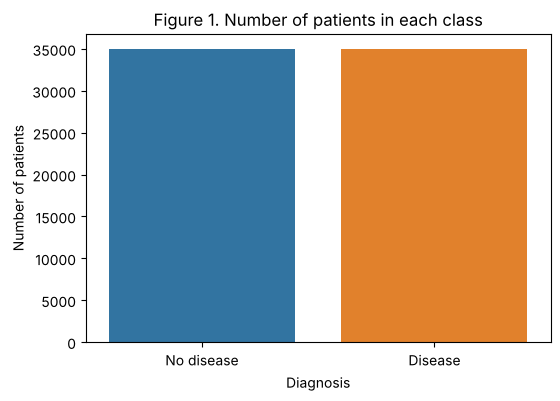

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=plot_df, x="Diagnosis", hue="Diagnosis", palette=class_colours, legend=False)
plt.title("Figure 1. Number of patients in each class")
plt.xlabel("Diagnosis")
plt.ylabel("Number of patients")
plt.show()

#### Figure 2 — Blood pressure before cleaning
Box plots summarise the spread of a variable and show individual extreme values as points. Here they show how far
some recorded blood pressure values lie from realistic readings.

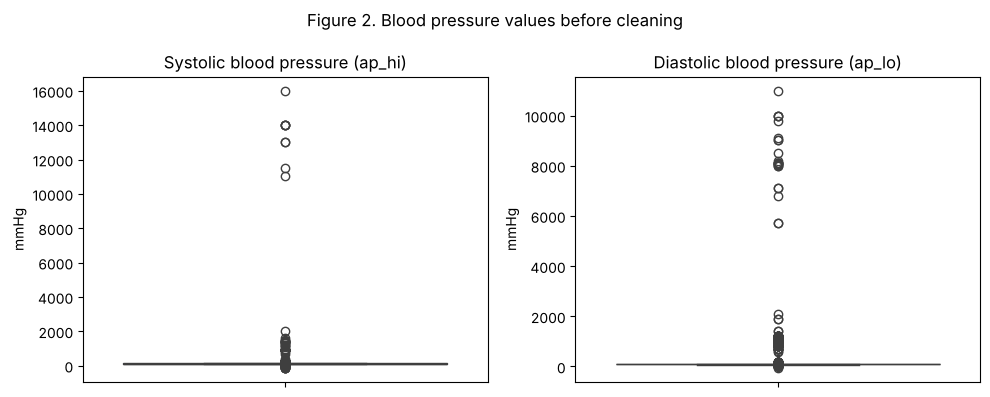

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=plot_df["ap_hi"], ax=axes[0], color="#1f77b4")
axes[0].set_title("Systolic blood pressure (ap_hi)")
axes[0].set_ylabel("mmHg")

sns.boxplot(y=plot_df["ap_lo"], ax=axes[1], color="#1f77b4")
axes[1].set_title("Diastolic blood pressure (ap_lo)")
axes[1].set_ylabel("mmHg")

fig.suptitle("Figure 2. Blood pressure values before cleaning")
plt.tight_layout()
plt.show()

#### Figure 3 — Disease rate by age group
Patients are grouped into five-year age bands, and for each band we compute the percentage of patients who
have the disease. This shows directly how the risk of disease changes with age.

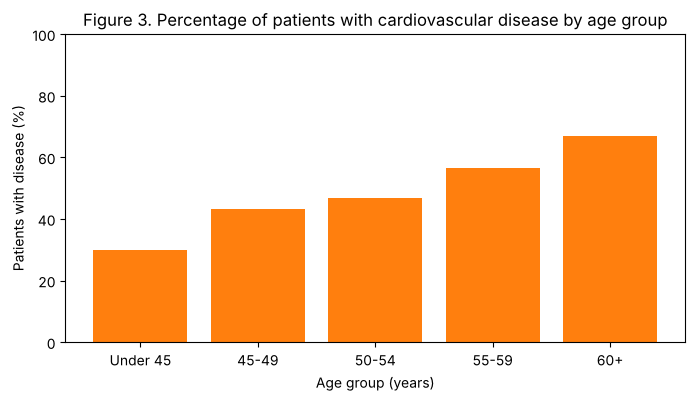

age_group
Under 45    29.8
45-49       43.1
50-54       46.7
55-59       56.7
60+         67.0
Name: cardio, dtype: float64

In [12]:
age_bins   = [0, 45, 50, 55, 60, 70]
age_labels = ["Under 45", "45-49", "50-54", "55-59", "60+"]
plot_df["age_group"] = pd.cut(plot_df["age_years"], bins=age_bins, labels=age_labels, right=False)

disease_rate_by_age = plot_df.groupby("age_group", observed=True)["cardio"].mean() * 100

plt.figure(figsize=(8, 4))
plt.bar(disease_rate_by_age.index, disease_rate_by_age.values, color="#ff7f0e")
plt.title("Figure 3. Percentage of patients with cardiovascular disease by age group")
plt.xlabel("Age group (years)")
plt.ylabel("Patients with disease (%)")
plt.ylim(0, 100)
plt.show()

disease_rate_by_age.round(1)

#### Figure 4 — Disease rate by cholesterol and glucose level
For each level of cholesterol and glucose, we compute the percentage of patients who have the disease.

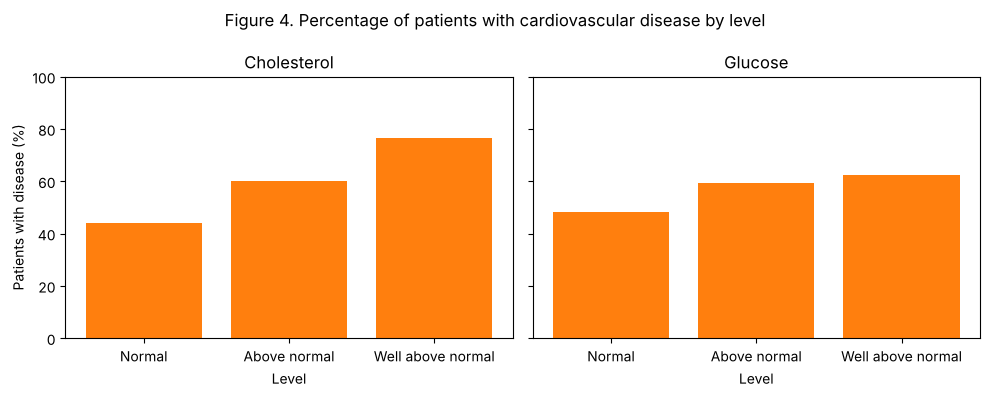

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
level_names = {1: "Normal", 2: "Above normal", 3: "Well above normal"}

for ax, column, title in zip(axes, ["cholesterol", "gluc"], ["Cholesterol", "Glucose"]):
    disease_rate = plot_df.groupby(column)["cardio"].mean() * 100
    ax.bar([level_names[level] for level in disease_rate.index], disease_rate.values, color="#ff7f0e")
    ax.set_title(title)
    ax.set_xlabel("Level")
    ax.set_ylim(0, 100)

axes[0].set_ylabel("Patients with disease (%)")
fig.suptitle("Figure 4. Percentage of patients with cardiovascular disease by level")
plt.tight_layout()
plt.show()

### 3.5 Key findings from the EDA

1. **No missing values.** All 70,000 records are complete, so no imputation is required.
2. **24 duplicate records** were found (ignoring `id`). These will be removed so that the same patient cannot
   appear in both the training and test sets.
3. **Implausible values are present but rare.** Blood pressure ranges from −150 to 16,020 mmHg (Section 3.1 and
   Figure 2), and some heights and weights are unrealistic. In total, **1,390 patients (1.99%)** fail at least one
   plausibility check. The most common problem is the diastolic value being greater than or equal to the systolic
   value (1,236 patients), which suggests the two values were often swapped or mistyped during data entry.
   Because these records represent only about 2% of the data, removing them will not meaningfully reduce the
   size or representativeness of the dataset.
4. **Age is related to the disease.** Almost all patients are between about 39 and 65 years old (only a few are younger, the youngest being about 30). Patients with the disease are
   older on average (about 54.9 years) than patients without it (about 51.7 years), and Figure 3 shows that the
   percentage of patients with the disease rises steadily with age, from 29.8% in the youngest group to 67.0%
   in patients aged 60 and over.
5. **Cholesterol and glucose are strongly related to the disease.** The percentage of patients with the disease rises
   from 44.0% at normal cholesterol to 76.5% at well-above-normal cholesterol, and from 48.1% to 62.2% for glucose
   (Figure 4). This supports treating these ordinal features as informative predictors.
6. **Gender coding.** The dataset does not state which code represents which gender. Patients coded `2` are on average
   about 8.6 cm taller than those coded `1` (169.9 cm vs 161.4 cm), which suggests that `2` corresponds to men and `1`
   to women. Code `1` is the larger group (45,530 vs 24,470 patients).
7. **Lifestyle features are imbalanced.** Only about 8.8% of patients report smoking and 5.4% report drinking alcohol,
   while 80.4% report being physically active. Because these features are self-reported and rare, they may carry less
   predictive information than the measured features.

## 4. Data Cleaning

The cleaning steps below apply the findings from Section 3. Each step uses a **fixed rule chosen in advance**
(for example, a fixed plausible range for blood pressure) rather than a value calculated from the data, such as
a mean or a percentile. Because fixed rules do not learn anything from the data, it is safe to apply them to
the whole dataset **before** splitting it. Any step that does learn from the data, such as scaling, is applied
only after the split, using the training set alone (Section 7).

| Step | Action | Reason |
|---|---|---|
| 1 | Remove the `id` column | It is a record number, not a patient characteristic, and has no predictive meaning |
| 2 | Remove duplicate records | Prevents the same patient from appearing in both training and test data. This is done **before** converting age, so that only records that are identical in the original data are removed |
| 3 | Convert `age` from days to years | Years are easier to interpret and to explain |
| 4 | Recode `gender` from 1/2 to 0/1 | Gives a clear binary feature: 1 = the group coded `2` in the original data (likely male, Section 3.5) |
| 5 | Remove records with implausible values | Removes data-entry errors identified in Section 3.3 (about 2% of records) |

In [14]:
clean_df = df.copy()   # keep the original df unchanged for reference
rows_start = len(clean_df)

# Step 1: remove the identifier column
clean_df = clean_df.drop(columns=["id"])

# Step 2: remove duplicate records (before any conversion, so only truly identical records are removed)
rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates()
duplicates_removed = rows_before - len(clean_df)

# Step 3: convert age from days to years
clean_df["age_years"] = clean_df["age"] / 365.25
clean_df = clean_df.drop(columns=["age"])

# Step 4: recode gender (1 -> 0, 2 -> 1)
clean_df["gender"] = clean_df["gender"].map({1: 0, 2: 1})

# Step 5: keep only records within the plausible ranges defined in Section 3.3
plausible = (
    clean_df["ap_hi"].between(70, 250) &
    clean_df["ap_lo"].between(40, 150) &
    (clean_df["ap_lo"] < clean_df["ap_hi"]) &
    clean_df["height"].between(120, 220) &
    clean_df["weight"].between(30, 200)
)
implausible_removed = (~plausible).sum()
clean_df = clean_df[plausible]

print("Rows at start:                 ", rows_start)
print("Duplicate rows removed:        ", duplicates_removed)
print("Implausible rows removed:      ", implausible_removed)
print("Rows after cleaning:           ", len(clean_df))
print("Percentage of data kept:       ", round(len(clean_df) / rows_start * 100, 2), "%")

Rows at start:                  70000
Duplicate rows removed:         24
Implausible rows removed:       1390
Rows after cleaning:            68586
Percentage of data kept:        97.98 %


In [15]:
# Check that the cleaning did not change the class balance
(clean_df["cardio"].value_counts(normalize=True) * 100).round(2)

cardio
0    50.52
1    49.48
Name: proportion, dtype: float64

Cleaning removed 1,414 records (24 duplicates and 1,390 records with implausible values), which is 2.02% of the data. The cleaned dataset contains 68,586 patients. The class balance is essentially unchanged, which
indicates that the removed records were not concentrated in one class and that the cleaned dataset remains
representative of the original.

## 5. Feature Engineering

We add two features that are commonly used in clinical practice and that combine existing columns into a
single, more meaningful value:

- **Body Mass Index (BMI)** = weight (kg) / height (m)². Height and weight on their own describe body size only
  partially; BMI relates the two and is a standard measure of whether a person is under- or overweight.
- **Pulse pressure** = systolic − diastolic blood pressure. A wide gap between the two readings is associated
  with stiffer arteries and increased cardiovascular risk.

These features are calculated row by row using a fixed formula, so, like the cleaning rules, they do not learn
anything from the data and can safely be added before the split.

In [16]:
clean_df["bmi"] = (clean_df["weight"] / (clean_df["height"] / 100) ** 2).round(1)
clean_df["pulse_pressure"] = clean_df["ap_hi"] - clean_df["ap_lo"]

clean_df[["height", "weight", "bmi", "ap_hi", "ap_lo", "pulse_pressure"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
height,68586.0,164.4,7.9,120.0,159.0,165.0,170.0,207.0
weight,68586.0,74.1,14.3,30.0,65.0,72.0,82.0,200.0
bmi,68586.0,27.5,5.3,10.7,23.9,26.3,30.1,108.2
ap_hi,68586.0,126.7,16.7,70.0,120.0,120.0,140.0,240.0
ap_lo,68586.0,81.3,9.4,40.0,80.0,80.0,90.0,150.0
pulse_pressure,68586.0,45.4,11.7,5.0,40.0,40.0,50.0,140.0


## 6. Train / Validation / Test Split

The cleaned data is divided into three separate sets, each with a different role:

| Set | Share | Role |
|---|---|---|
| **Training** | 60% | Used to fit (train) every model |
| **Validation** | 20% | Used to compare models and choose settings |
| **Test** | 20% | Held back and used **only once**, at the end of the project, to report final performance |

Keeping the test set untouched until the end is essential: if it were used to make any decision, such as which
model to keep, the final score would no longer reflect performance on truly unseen patients and would be overly
optimistic. The validation set takes on that role instead.

The split is **stratified** on `cardio`, which means each set keeps the same proportion of patients with and
without the disease, so no set is accidentally easier or harder than the others. The split uses the fixed
`random_state=SEED`, which **freezes** it: every run of this notebook produces exactly the same three sets, and
all models in the project are trained and evaluated on the same patients.

The split is done in two stages: first 60% training and 40% remaining, then the remaining 40% is divided equally
into validation and test (20% each). The target column is removed from the inputs **by name**, which guarantees
that the answer cannot accidentally be included as a feature.

In [17]:
from sklearn.model_selection import train_test_split

X = clean_df.drop(columns=["cardio"])   # input features
y = clean_df["cardio"]                  # target

# Stage 1: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)

# Stage 2: split the temporary 40% into 20% validation and 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Features used:", list(X.columns))

Features used: ['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi', 'pulse_pressure']


**Table 1. Size and class balance of each set**

In [18]:
split_table = pd.DataFrame({
    "Set": ["Training", "Validation", "Test"],
    "Patients": [len(X_train), len(X_val), len(X_test)],
    "Share of data (%)": [round(len(s) / len(X) * 100, 1) for s in [X_train, X_val, X_test]],
    "With disease (%)": [round(s.mean() * 100, 2) for s in [y_train, y_val, y_test]],
})
split_table

,Set,Patients,Share of data (%),With disease (%)
0,Training,41151,60.0,49.48
1,Validation,13717,20.0,49.48
2,Test,13718,20.0,49.48


## 7. Feature Scaling

The features are measured on very different scales: for example, systolic blood pressure is around 120, while
`smoke` is either 0 or 1. Several of our models are sensitive to this:

- **KNN** and **SVM** are based on distances between patients, so a feature with large numbers would dominate
  the distance simply because of its units.
- **Logistic regression** is trained with gradient-based optimisation, which converges faster and more reliably
  when features are on a similar scale.

We use `StandardScaler`, which transforms each feature to have a mean of 0 and a standard deviation of 1.

**The scaler is fitted on the training set only.** Fitting means calculating each feature's mean and standard
deviation. If the validation or test data were included in this calculation, information from those sets would
leak into training, and our evaluation would be overly optimistic. The scaler therefore *learns* from the training
set (`fit_transform`) and is then only *applied* to the validation and test sets (`transform`).

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean and std from the TRAINING set only
X_val_scaled   = scaler.transform(X_val)         # apply the same transformation
X_test_scaled  = scaler.transform(X_test)        # applied now, but NOT used until the final evaluation

# Check: training features now have mean ~0 and standard deviation ~1
print("Mean of scaled training features (first 5):", X_train_scaled.mean(axis=0)[:5].round(3))
print("Std of scaled training features (first 5): ", X_train_scaled.std(axis=0)[:5].round(3))

Mean of scaled training features (first 5): [-0. -0.  0. -0. -0.]
Std of scaled training features (first 5):  [1. 1. 1. 1. 1.]


Since the dataset contains no missing values (Section 3.2), no imputer is required. If one were needed, it would
follow the same rule as the scaler and be fitted on the training set only.

## 8. Evaluation Setup

### 8.1 Choice of metrics
In this problem, the **positive class** is `cardio = 1` (the patient has cardiovascular disease). Every prediction falls
into one of four groups: true positive, true negative, false positive (a false alarm) or false negative (a sick patient
who is missed). We report four metrics, all computed on the **validation set**:

| Metric | Question it answers | Why we use it |
|---|---|---|
| **Accuracy** | What proportion of all patients are classified correctly? | Easy to interpret, and a fair summary here because the classes are balanced (Section 2.3) |
| **Precision** | Of the patients predicted to have the disease, what proportion actually have it? | Measures how many alarms are false alarms |
| **Recall** | Of the patients who actually have the disease, what proportion are detected? | **Most important for screening:** a missed patient (false negative) may go untreated, which is more harmful than a false alarm that leads to a follow-up test |
| **F1 score** | Harmonic mean of precision and recall | A single number that is only high when both precision and recall are high; used as our main score for comparing models, so that a model cannot score well simply by predicting "disease" for everyone |

### 8.2 Fair comparison
To compare models fairly, every model is evaluated by the same function, with the same training data, the same
validation data and the same metrics. The function also records:
- **Training time**: how long the model takes to fit.
- **Prediction (inference) time**: how long the model takes to classify the validation set.

Times are measured with `time.perf_counter()` and depend on the computer used, so they are meaningful for comparing
models within this notebook rather than as absolute values.

In [20]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(name, model, X_tr, y_tr, X_ev, y_ev):
    """Train a model, predict on the evaluation set, and return its scores and timings."""
    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = model.predict(X_ev)
    predict_time = time.perf_counter() - start

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_ev, y_pred),
        "Precision": precision_score(y_ev, y_pred, zero_division=0),
        "Recall": recall_score(y_ev, y_pred),
        "F1": f1_score(y_ev, y_pred),
        "Train time (s)": train_time,
        "Predict time (s)": predict_time,
    }

results = []   # one row per model, used to build the comparison table

## 9. Baseline Models

We train four baseline models. All are trained on the scaled training set and evaluated on the validation set.

| Model | How it works | Why it is included |
|---|---|---|
| **Dummy classifier** | Always predicts the most frequent class in the training set | A reference point: any useful model must clearly outperform it |
| **Logistic regression** | Computes a weighted sum of the features and passes it through the sigmoid function to obtain the probability of disease; the weights are learned by maximum likelihood (minimising cross-entropy loss) | The standard linear classifier and a natural first model for a binary problem |
| **K-Nearest Neighbours (KNN)** | Classifies a patient by a majority vote of the *k* most similar patients in the training set | A simple, non-parametric model that makes no assumption about the shape of the decision boundary |
| **Linear Support Vector Machine (SVM)** | Finds the linear decision boundary with the widest possible margin between the two classes | A strong linear classifier; the linear version (`LinearSVC`) scales well to a dataset of this size |

### 9.1 Dummy classifier

In [21]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
results.append(evaluate_model("Dummy (most frequent)", dummy, X_train_scaled, y_train, X_val_scaled, y_val))
results[-1]

{'Model': 'Dummy (most frequent)',
 'Accuracy': 0.5052125100240578,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0,
 'Train time (s)': 0.0008638960000553197,
 'Predict time (s)': 8.850799997617287e-05}

The dummy classifier always predicts the majority class of the training set (no disease), so it never detects
a patient with the disease. Its recall and F1 score are therefore 0, and its accuracy (about 50%) is the level any
real model must beat.

### 9.2 Logistic regression

In [22]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=SEED)
results.append(evaluate_model("Logistic Regression", log_reg, X_train_scaled, y_train, X_val_scaled, y_val))
results[-1]

{'Model': 'Logistic Regression',
 'Accuracy': 0.7303346212728731,
 'Precision': 0.7550379914106375,
 'Recall': 0.6734934433475762,
 'F1': 0.7119383225605482,
 'Train time (s)': 0.1381491009999536,
 'Predict time (s)': 0.0006138579999515059}

**Learned coefficients.** Because the features are standardised, the size of each coefficient shows how strongly
that feature pushes the prediction towards disease (positive) or no disease (negative).

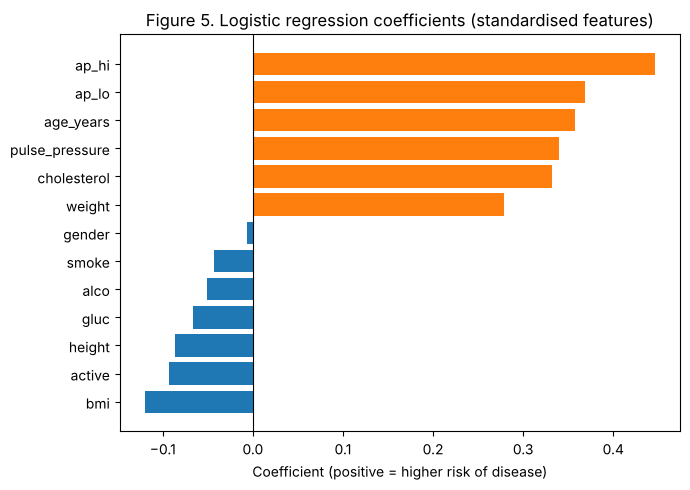

In [23]:
coefficients = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(7, 5))
plt.barh(coefficients.index, coefficients.values,
         color=["#1f77b4" if v < 0 else "#ff7f0e" for v in coefficients.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Figure 5. Logistic regression coefficients (standardised features)")
plt.xlabel("Coefficient (positive = higher risk of disease)")
plt.tight_layout()
plt.show()

The largest positive coefficients belong to systolic blood pressure, diastolic blood pressure, age, pulse pressure,
cholesterol and weight, so higher values of these features increase the predicted risk of disease. Coefficients
should be interpreted with some caution, however: several features are closely related to each other (for example,
`bmi` is calculated from `height` and `weight`, and `pulse_pressure` from the two blood pressure values). When features
overlap like this, the model can split their effect between them in different ways, so the sign or size of an individual
coefficient (such as the small negative values for `bmi` and `gluc`) does not necessarily reflect that feature's
relationship with the disease on its own.

### 9.3 K-Nearest Neighbours
The number of neighbours *k* must be chosen. A small *k* follows individual training points closely and tends to
overfit, while a large *k* smooths over real patterns and tends to underfit. We compare several values of *k* on the
**validation set** and keep the one with the highest F1 score.

In [24]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [5, 15, 25, 51, 101]
knn_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    knn_scores.append(f1_score(y_val, knn.predict(X_val_scaled)))

knn_table = pd.DataFrame({"k": k_values, "Validation F1": knn_scores}).round(4)
best_k = int(knn_table.loc[knn_table["Validation F1"].idxmax(), "k"])
print("Best k:", best_k)
knn_table

Best k: 51


,k,Validation F1
0,5,0.6928
1,15,0.7160
2,25,0.7151
3,51,0.7214
4,101,0.7175


In [25]:
knn = KNeighborsClassifier(n_neighbors=best_k)
results.append(evaluate_model(f"KNN (k={best_k})", knn, X_train_scaled, y_train, X_val_scaled, y_val))
results[-1]

{'Model': 'KNN (k=51)',
 'Accuracy': 0.7353648757016841,
 'Precision': 0.7529242108636437,
 'Recall': 0.6923530278473552,
 'F1': 0.7213693583051888,
 'Train time (s)': 0.10108445599996685,
 'Predict time (s)': 3.8489024399999607}

### 9.4 Linear Support Vector Machine
We use `LinearSVC` with its default regularisation strength (`C = 1.0`). A standard kernel SVM (`SVC`) becomes very
slow on tens of thousands of training samples, whereas `LinearSVC` trains in seconds on the full training set.

In [26]:
from sklearn.svm import LinearSVC

svm = LinearSVC(C=1.0, max_iter=5000, random_state=SEED)
results.append(evaluate_model("Linear SVM", svm, X_train_scaled, y_train, X_val_scaled, y_val))
results[-1]

{'Model': 'Linear SVM',
 'Accuracy': 0.7295326966537873,
 'Precision': 0.7586148932593714,
 'Recall': 0.6649476941211139,
 'F1': 0.7086997487437185,
 'Train time (s)': 0.04381031900004473,
 'Predict time (s)': 0.0007640710000487161}

### 9.5 Model comparison

**Number of learned parameters.**
- Logistic regression and the linear SVM each learn one weight per feature plus one intercept
  (13 features → 14 parameters).
- KNN learns no parameters: it stores the entire training set and does all its work at prediction time.
- The dummy classifier learns only which class is most frequent.

In [27]:
n_features = X_train_scaled.shape[1]
parameter_counts = {
    "Dummy (most frequent)": 0,
    "Logistic Regression": log_reg.coef_.size + log_reg.intercept_.size,
    f"KNN (k={best_k})": 0,
    "Linear SVM": svm.coef_.size + svm.intercept_.size,
}

comparison = pd.DataFrame(results)
comparison["Learned parameters"] = comparison["Model"].map(parameter_counts)
dummy_accuracy = comparison.loc[comparison["Model"] == "Dummy (most frequent)", "Accuracy"].iloc[0]
comparison["Accuracy gain over dummy (pts)"] = (comparison["Accuracy"] - dummy_accuracy) * 100

print("Table 2. Baseline model comparison on the validation set")
comparison.round(4)

Table 2. Baseline model comparison on the validation set


,Model,Accuracy,Precision,Recall,F1,Train time (s),Predict time (s),Learned parameters,Accuracy gain over dummy (pts)
0,Dummy (most frequent),0.5052,0.0000,0.0000,0.0000,0.0009,0.0001,0,0.0000
1,Logistic Regression,0.7303,0.7550,0.6735,0.7119,0.1381,0.0006,14,22.5122
2,KNN (k=51),0.7354,0.7529,0.6924,0.7214,0.1011,3.8489,0,23.0152
3,Linear SVM,0.7295,0.7586,0.6649,0.7087,0.0438,0.0008,14,22.4320


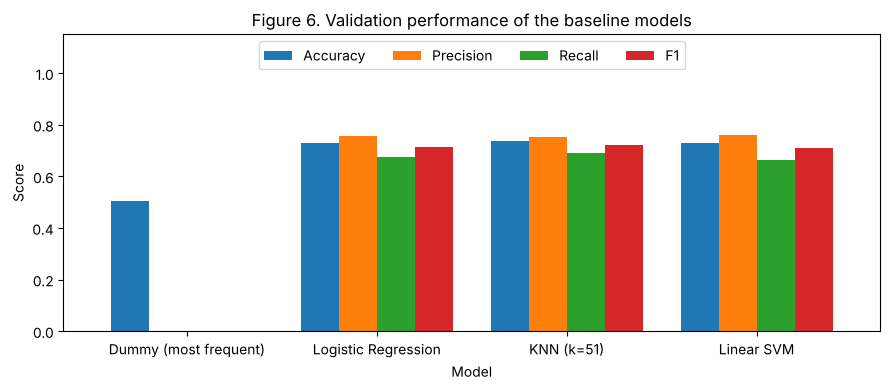

In [28]:
# Visual comparison of the four metrics
metrics = ["Accuracy", "Precision", "Recall", "F1"]
comparison.set_index("Model")[metrics].plot(kind="bar", figsize=(9, 4), rot=0, width=0.8)
plt.title("Figure 6. Validation performance of the baseline models")
plt.ylabel("Score")
plt.ylim(0, 1.15)
plt.legend(loc="upper center", ncol=4)
plt.tight_layout()
plt.show()

### 9.6 Confusion matrix of the best baseline model
The confusion matrix shows the four types of prediction for the model with the highest validation F1 score.
Rows are the **actual** classes and columns are the **predicted** classes. The bottom-left cell (actual disease,
predicted no disease) contains the **false negatives**, the most important type of error for a screening tool.

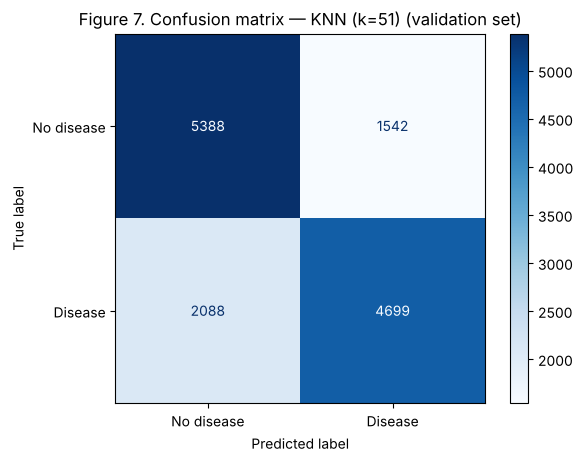

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

trained_models = {"Logistic Regression": log_reg, f"KNN (k={best_k})": knn, "Linear SVM": svm}
best_name = comparison.drop(index=0).sort_values("F1", ascending=False)["Model"].iloc[0]
best_model = trained_models[best_name]

ConfusionMatrixDisplay.from_estimator(
    best_model, X_val_scaled, y_val,
    display_labels=["No disease", "Disease"], cmap="Blues")
plt.title(f"Figure 7. Confusion matrix — {best_name} (validation set)")
plt.show()

## 10. Stage 1 Summary

### Conclusion
All three trained models clearly outperform the dummy baseline, improving validation accuracy by about 22–23
percentage points (from 50.5% to about 73%). Their performance is very similar (F1 between 0.709 and 0.721), which
suggests that, at this stage, the limiting factor is the information contained in the features rather than the
choice of model. **KNN (k = 51)** achieved the highest validation F1 (0.721) and recall (0.692), but it is by far the
slowest at prediction time, because it must compare every new patient with all 41,000 training patients.
**Logistic regression** performs almost as well (F1 = 0.712), predicts several thousand times faster and is easy to
interpret, since its coefficients show which features increase risk. The strongest predictors are systolic and
diastolic blood pressure, age, pulse pressure, cholesterol and weight (Figure 5), which is consistent with the
EDA findings in Section 3.5.

### Open risks and next steps
- **Recall is too low for a screening tool.** Even the best model misses about 31% of patients who have the disease
  (2,088 false negatives out of 6,787 patients with the disease in the validation set, Figure 7). In Stage 2 we will
  investigate whether more flexible models, or a lower decision threshold, can detect more of these patients
  without producing an unacceptable number of false alarms.
- **Linear models may be too simple.** Logistic regression and the linear SVM can only draw a straight decision
  boundary. Tree-based models and a neural network (Stage 2) can capture non-linear relationships, such as risk rising
  sharply above a certain blood pressure.
- **Data reliability.** Smoking, alcohol intake and physical activity are self-reported and may be inaccurate. In addition,
  some remaining combinations of height and weight produce extreme BMI values (up to about 108), which are likely
  entry errors that our individual range checks did not catch.
- **The test set has not been used.** All results above are on the validation set; the test set remains untouched
  until the final evaluation in Stage 3.